 # ML Workflow

  Dataset
    →
  Understand columns
    →
  Clean data
    →
  Handle missing values
    →
  EDA
    →
  Identify target column
    →
  Separate X and y
    →
  Encode categorical columns
    →
  Train/Test Split
    →
  Feature Scaling (if required)
    →
  Train ML model
    →
  Prediction
    →
  Evaluate model

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [50]:
df = pd.read_table("/content/50_Startups.csv",sep=",")

In [51]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB




*   For this dataset i get know that there are 50 rows of rows with 5 columns. four float and one objects columns. that is no null value



In [53]:
df.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000




*   by describe i get know that some columns have skweness



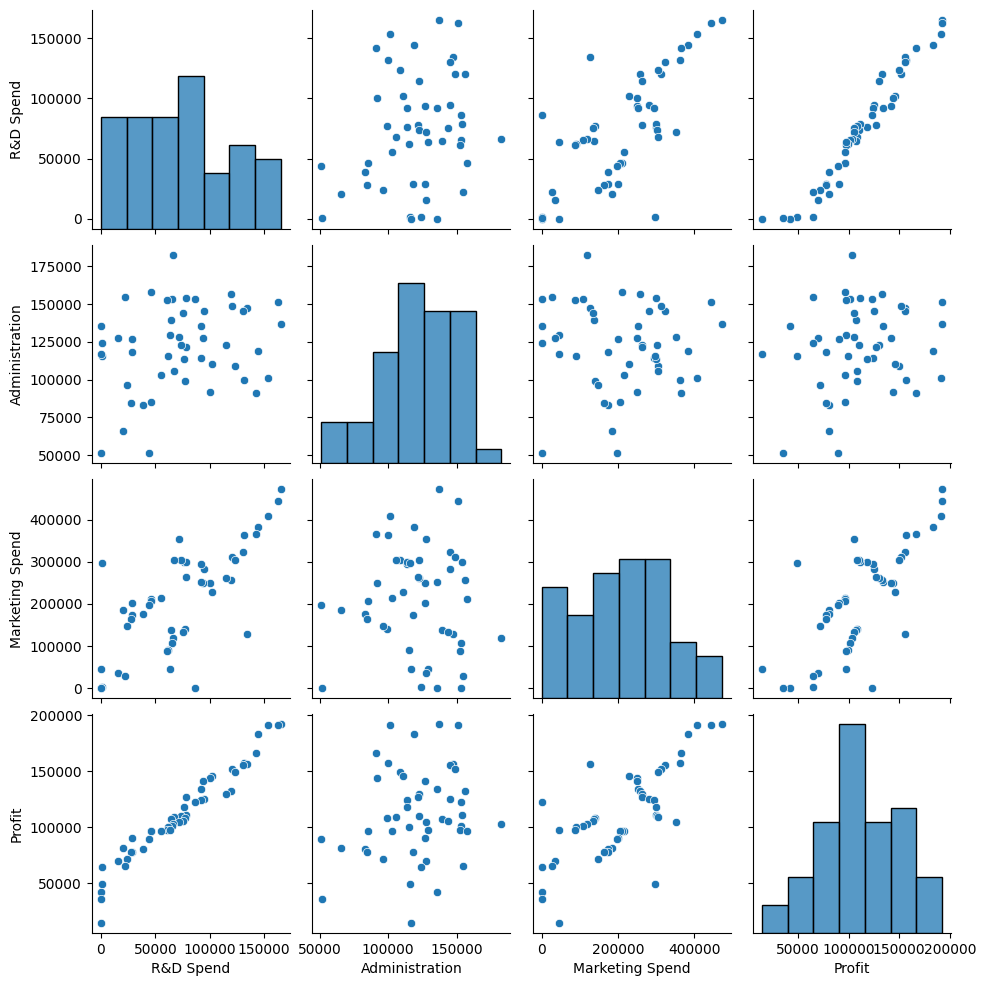

In [54]:
sns.pairplot(df)

In [55]:
num_col=df.columns[df.dtypes!=object]
num_col

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit'], dtype='object')



*   checking the correlated with heatmap of all numerical columns



<Axes: >

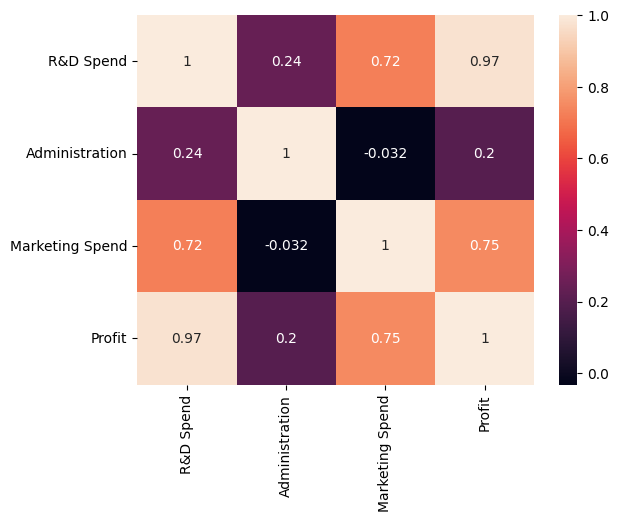

In [56]:
sns.heatmap(df[num_col].corr(), annot=True)



*   checking outlier with boxplot of numerical columns



<Axes: >

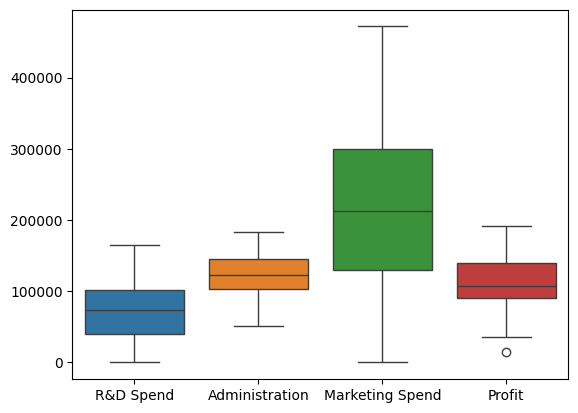

In [57]:
sns.boxplot(df)



*   checking skewness with distplot of numerical columns



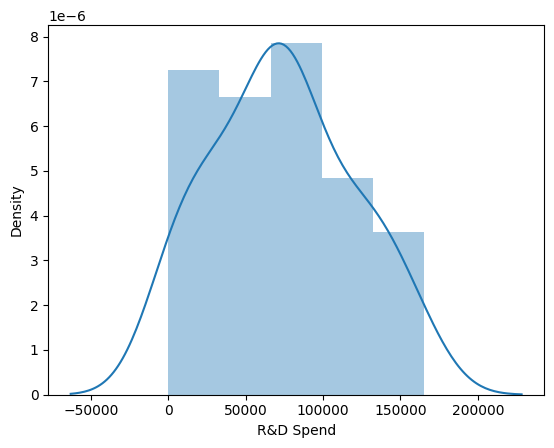

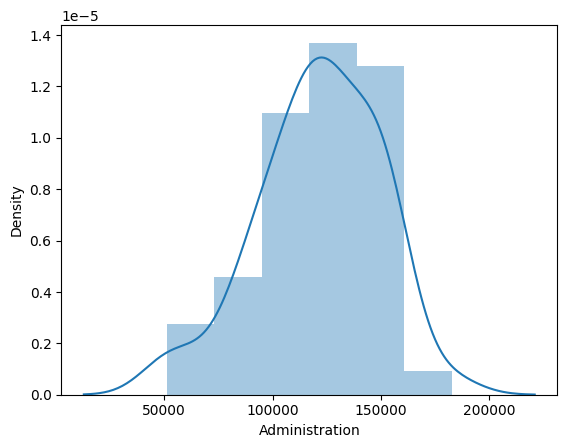

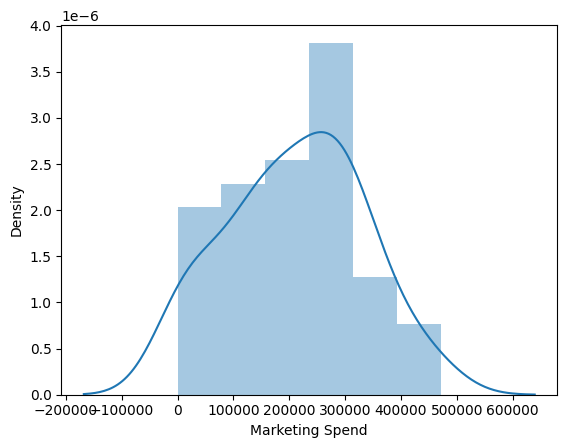

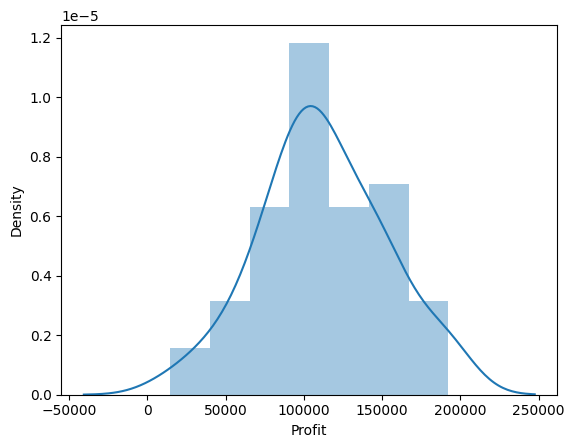

In [58]:
for i in num_col:
  sns.distplot(df[i])
  plt.show()



*   Converting 'State' objects columns into numerical columns by applying One Hot Encoder



In [59]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(
    sparse_output=False,
    drop="first"
)

state_encoded = ohe.fit_transform(df[["State"]])

state_encoded_df = pd.DataFrame(
    state_encoded,
    columns=ohe.get_feature_names_out(),
    index=df.index
)

df = pd.concat([df, state_encoded_df], axis=1)

df.drop("State", axis=1, inplace=True)

In [60]:
df.head()

,R&D Spend,Administration,Marketing Spend,Profit,State_Florida,State_New York
0,165349.20,136897.80,471784.10,192261.83,0.0,1.0
1,162597.70,151377.59,443898.53,191792.06,0.0,0.0
2,153441.51,101145.55,407934.54,191050.39,1.0,0.0
3,144372.41,118671.85,383199.62,182901.99,0.0,1.0
4,142107.34,91391.77,366168.42,166187.94,1.0,0.0




*   Check skewness of numerical columns



In [61]:
# Check skewness of numerical columns
skewness = df.select_dtypes(include='number').skew()
print(skewness)

R&D Spend          0.164002
Administration    -0.489025
Marketing Spend   -0.046472
Profit             0.023291
State_Florida      0.795820
State_New York     0.696595
dtype: float64




*   Check skewness of 'Administration' columns




In [62]:
print("Before:", df["Administration"].skew())

Before: -0.4890248099671768


*   Check skewness of 'Administration' columns with distplot

<Axes: xlabel='Administration', ylabel='Density'>

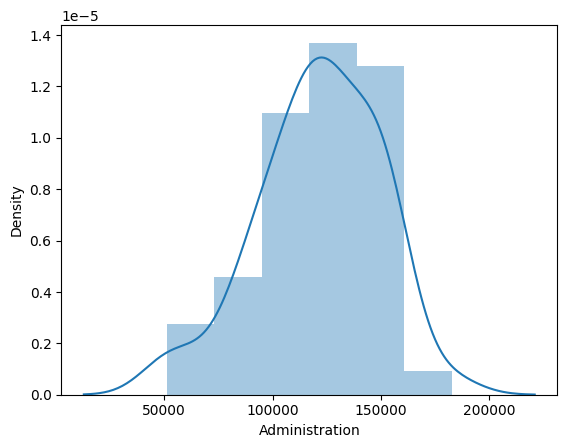

In [63]:
sns.distplot(df["Administration"])

*   Spelling data in X and Y

In [64]:
dfX = df.drop("Profit", axis=1)
dfY = df["Profit"]
X = dfX.iloc[:, :]
Y = dfY.iloc[:]

In [65]:
Y.head()

,Profit
0,192261.83
1,191792.06
2,191050.39
3,182901.99
4,166187.94
5,156991.12
6,156122.51
7,155752.60
8,152211.77
9,149759.96


*   Div X and Y data in Training and Testing data

In [66]:
from sklearn.model_selection import train_test_split
# Split using the updated X and Y variables
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=1)

*   Makeing user define function to train the model by Linear Redgression

In [67]:
def EnterModel(model):
  model.fit(X_train,Y_train)
  ypred = model.predict(X_test)
  from sklearn.metrics import r2_score
  r2 = r2_score(Y_test, ypred)
  train = model.score(X_train, Y_train)
  test = model.score(X_test, Y_test)
  print("R2 Score:", r2)
  print()
  print("Train Score:", train)
  print("Test Score:", test)
  return r2



*   Use the function on Linear Regression



In [68]:
from sklearn.linear_model import LinearRegression
lr = EnterModel(LinearRegression())

R2 Score: 0.9649618042059875

Train Score: 0.942446542689397
Test Score: 0.9649618042059875




*   After train the model i get 94.2% Training with 96.4% Testing Accuracy.
*   The model is given Overfit
*   To fix the Overfit i use the Ridge Method



In [69]:
from sklearn.linear_model import Ridge
L2 = Ridge(alpha=10)
L2.fit(X_train,Y_train)
y_pred = L2.predict(X_test)
from sklearn.metrics import r2_score
r2= r2_score(Y_test,y_pred)
train= L2.score(X_train,Y_train)
test= L2.score(X_test,Y_test)
print(f"R2 score is {r2}")
print()
print(f"train score is {train}")
print(f"test score is {test}")

R2 score is 0.9650576202255771

train score is 0.9424301355468502
test score is 0.9650576202255771




*   After use Ridge i get some Accuracy.
*   To make prediction i make a user define function.
*   The function take input, apply encodeing, train new enter value.
*   Make Predition for the new enter value.



In [70]:
def predict_profit(rnd_spend, administration, marketing_spend, state):

    # Encode State
    state_encoded = ohe.transform([[state]])

    # Create numerical input
    input_data = pd.DataFrame(
        [[rnd_spend, administration, marketing_spend]],
        columns=["R&D Spend", "Administration", "Marketing Spend"]
    )

    # Create encoded State DataFrame
    state_encoded_df = pd.DataFrame(
        state_encoded,
        columns=ohe.get_feature_names_out()
    )

    # Combine everything
    input_data = pd.concat(
        [
            input_data.reset_index(drop=True),
            state_encoded_df.reset_index(drop=True)
        ],
        axis=1
    )

    # Prediction
    lr = LinearRegression()
    lr.fit(X_train, Y_train)
    lr.fit(X_train, Y_train)
    prediction = lr.predict(input_data)

    return prediction[0]



*   Given new Value to function and take the prediction result



In [71]:
result = predict_profit(
    100000,
    120000,
    200000,
    "New York"
)
print(f"Prediction Profit: ₹{result:.2f}")

Prediction Profit: ₹131907.13
